## Time Series Analysis

### Initialization

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utilsforecast.plotting import plot_series
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import *

from statsforecast import StatsForecast
from statsforecast.models import Naive, HistoricAverage, WindowAverage, SeasonalNaive

from statsforecast.models import AutoARIMA

import warnings
warnings.filterwarnings("ignore")

c:\Users\revan\anaconda3\envs\time_series_analysis_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
data_path = r'data/daily_sales_french_bakery.csv'

In [ ]:
def line_plot_forecast(source_df, cv_df, max_insample_length = 140):
    return plot_series(
        df = source_df, 
        forecasts_df = cv_df.drop(["y", "cutoff"], axis = 1),
        ids = ["BAGUETTE", "CROISSANT"], 
        palette = "viridis",
        max_insample_length = 140
    )

In [3]:
def bar_chart_eval_viz(eval_df, figsize):
    methods = eval_df.columns[1:].tolist()
    values = eval_df.iloc[0,1:].tolist()

    plt.figure(figsize=figsize)
    bars = plt.bar(methods, values)

    for bar, value in zip(bars,values):
        plt.text(bar.get_x() + bar.get_width()/2, 
                bar.get_height() + 0.05,
                f'{value : .3f}',
                ha = 'center',
                va = 'bottom',
                fontweight = 'bold'
                )

    plt.xlabel('Methods')
    plt.ylabel('Mean Absolute Error (MAE)')
    plt.tight_layout()

    plt.show()

In [4]:
def data_cleaning(data_path):
    df = pd.read_csv(data_path, parse_dates = ["ds"])
    grouped_df = df.groupby("unique_id").filter(lambda x : len(x) >= 28).reset_index() # fitlering out products that have fewer than 28 historical data points
    grouped_df = grouped_df.drop(columns = ["unit_price"])

    return grouped_df

data_path = r'data/daily_sales_french_bakery.csv'
grouped_df = data_cleaning(data_path)

### Data Cleaning

In [4]:
df = pd.read_csv("data/daily_sales_french_bakery.csv", parse_dates = ["ds"])
df.head()

,unique_id,ds,y,unit_price
0,12 MACARON,2022-07-13,10.0,10.0
1,12 MACARON,2022-07-14,0.0,10.0
2,12 MACARON,2022-07-15,0.0,10.0
3,12 MACARON,2022-07-16,10.0,10.0
4,12 MACARON,2022-07-17,30.0,10.0


In [3]:
df.shape

(57046, 4)

In [ ]:
grouped_df = df.groupby("unique_id").filter(lambda x : len(x) >= 28).reset_index() # fitlering out products that have fewer than 28 historical data points
grouped_df = grouped_df.drop(columns = ["unit_price"])

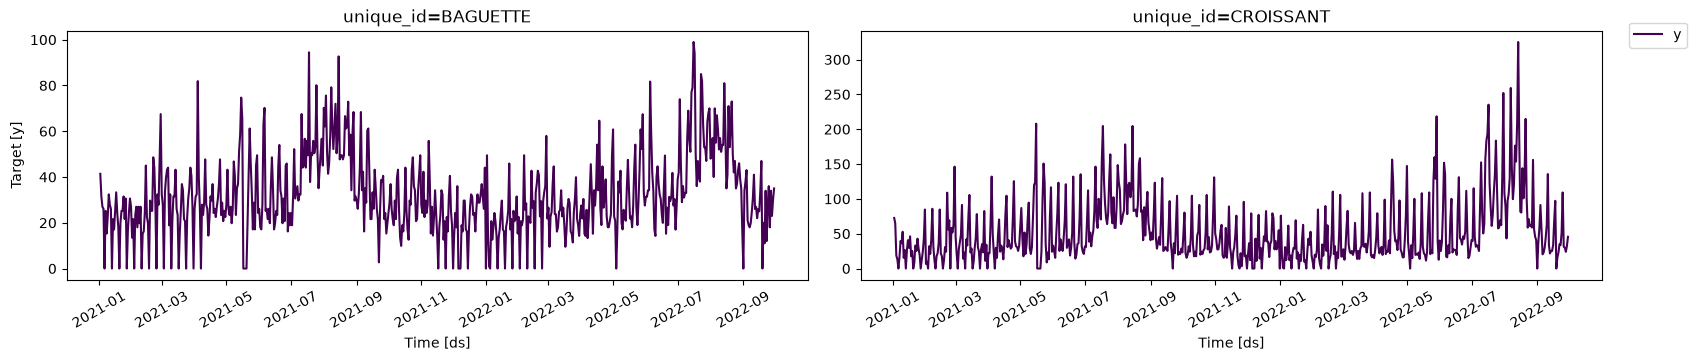

In [16]:
plot_series(df = grouped_df, ids = ["BAGUETTE", "CROISSANT"], palette = "viridis")

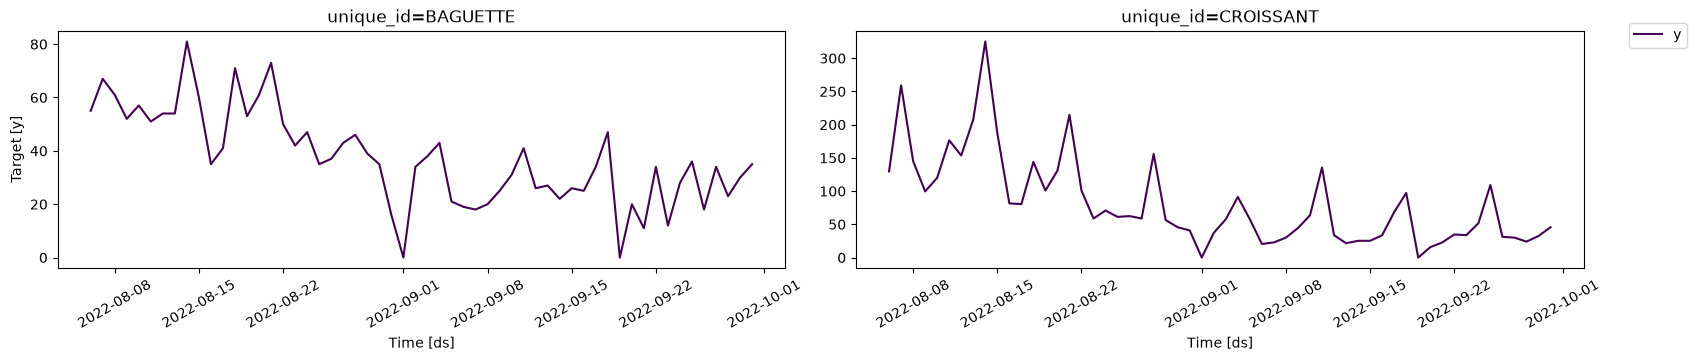

In [ ]:
plot_series(
    df = grouped_df, 
    ids = ["BAGUETTE", "CROISSANT"], 
    palette = "viridis", 
    max_insample_length = 56 # only plotting the last 56 timestamps
)

### Baseline Models

In [5]:
data_path = r'data/daily_sales_french_bakery.csv'
grouped_df = data_cleaning(data_path)

Imagine you are tracking daily croissant sales for the past two weeks, giving you this sequence of 14 numbers:
$$[10, 12, 15, 14, 13, 20, 25, 11, 13, 16, 15, 14, 22, 26]$$
(Notice how sales spike on days 7 and 14—likely weekends!)
Here is how each baseline model uses this history to forecast sales for Day 15 (Sunday):
1. **Naive()**      
    - How it works: Predicts that tomorrow will look exactly like the very last observed day.     
    - Calculation: Takes the value of Day 14 ($26$).      
    - Prediction for Day 15: $26$             
    - *Best used for: Highly volatile data where the latest value is the strongest clue.*       

2. **HistoricAverage()**     
    - How it works: Takes the average (mean) of all available past data points.       
    - Calculation: The average of all 14 numbers.     
    - Prediction for Day 15: $16.5$       
    - *Best used for: Stable, flat data with no strong trends or seasonality.*      

3. **WindowAverage(window_size = 7)**      
    - How it works: Takes the rolling average of only the most recent $N$ days (in this case, the last 7 days: days 8 through 14, which are $[11, 13, 16, 15, 14, 22, 26] $).     
    - Calculation: $\frac{11 + 13 + 16 + 15 + 14 + 22 + 26}{7}$       
    - Prediction for Day 15: $16.71$      
    - *Best used for: Capturing short-term momentum or recent shifts while smoothing out daily noise.*    

4. **SeasonalNaive(season_length = 7)**
    - How it works: Looks backward by a specific seasonal period (7 days, representing a weekly cycle) and copies that exact day's value. Since Day 15 is a Sunday, it looks back 7 days to the previous Sunday (Day 8).
    - Calculation: Takes the value of Day 8 ($11$).
    - Prediction for Day 15: $11$ (Note: If forecasting Day 16/Monday, it would look back to Day 9/Monday, which is $13$).
    - *Best used for: Data with strong recurring patterns, like weekly shopping behavior or monthly cycles.*

In [6]:
horizon = 7 # forecast horizon of 7 days

models = [
    Naive(),                            # Uses the most recent observed value.
    HistoricAverage(),                  # Uses the mean of all past values.
    WindowAverage(window_size = 7),     # Uses a rolling average over the last 7 days.
    SeasonalNaive(season_length = 7)    # Uses the value from the exact same day in the previous week (capturing weekly seasonality).
]

sf = StatsForecast(models = models, freq = "D") # D = daily frequency
sf.fit(df = grouped_df)
preds = sf.predict(h = horizon) # generates forecasts for the next 7 days

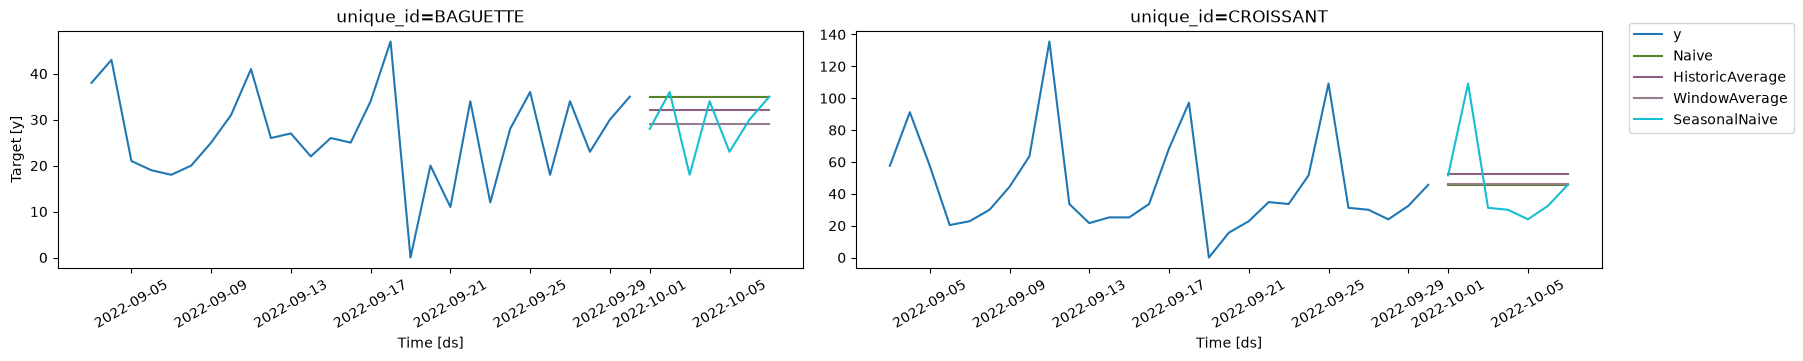

In [30]:
plot_series(
    df = grouped_df, 
    forecasts_df = preds,
    ids = ["BAGUETTE", "CROISSANT"], 
    # palette = "viridis", 
    max_insample_length = 28 # only plotting the last 56 timestamps
)

### Evaluating Baseline Models

In [7]:
test = grouped_df.groupby("unique_id").tail(horizon)  # taking the last 7 records of each item as the test set
train = grouped_df.drop(test.index, axis = 0).reset_index(drop = True)

In [ ]:
# StatsForecast follows a predefined data schema. It expects the target variable to be named y. Hence you don't explicitly mention the target column.
sf.fit(df = train) # Trains the baseline models using only the historical data.
preds = sf.predict(h=horizon) # Generates forecasts for the upcoming horizon (in this case, next 7 day predictions for each unique_id).
eval_df = pd.merge(test, preds, 'left', ['ds', 'unique_id']) # Matches the model's predictions side-by-side with the actual values from the test set

In [11]:
# calculates mae to indicate, on average, how many units off the forecasts were from actual sales.
evaluation = evaluate(
    eval_df,
    metrics = [mae],
)

evaluation.head()

,unique_id,metric,index,Naive,HistoricAverage,WindowAverage,SeasonalNaive
0,12 MACARON,mae,71.142857,2.857143,6.961771,3.469388,4.285714
1,BAGUETTE,mae,687.857143,17.142857,5.455193,7.877551,12.571429
2,BAGUETTE APERO,mae,1243.000000,0.000000,0.537572,0.642857,0.642857
3,BAGUETTE GRAINE,mae,1872.200000,9.800000,4.612271,2.942857,0.200000
4,BANETTE,mae,2477.814286,1.314286,5.421984,6.008163,7.885714


In [15]:
evaluation = evaluation.drop(columns = ['unique_id', 'index'], axis= 1).groupby('metric').mean().reset_index()
evaluation

,metric,Naive,HistoricAverage,WindowAverage,SeasonalNaive
0,mae,6.107556,5.228439,5.011663,4.613636


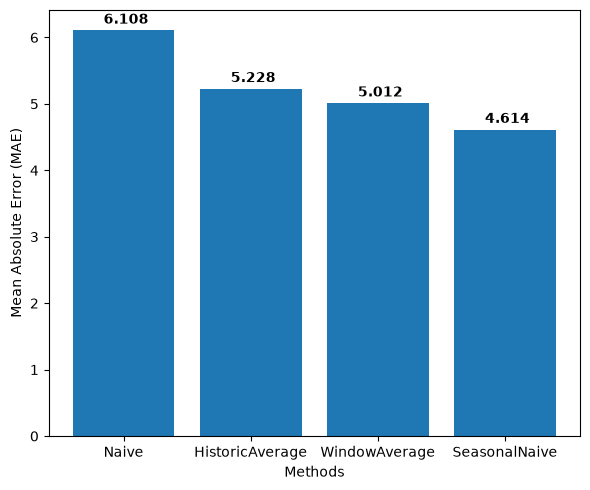

In [51]:
bar_chart_eval_viz(evaluation, (6,5))

Since Seasonal Naive gives the lowest MAE Score, we will choose that as our Benchmark Model.

### ARIMA (AutoRegressive Integrated Moving Average)

**AR (autoregressive model) :**         
- future values of the series depend on past values.
- denoted as (p) - order of the autoregressive model (how many past time steps are used to predict the future value)

**MA (moving average) :**       
- future values depend on present and past error terms. Predictions are influences by past error terms.
- errors are independent and normally distributed.
- denoted as (q) - order of moving average model

**ARMA model:**     
When we combine the 2 models we get the ARMA model: AR(p) + MA(q) = ARMA (p,q)      

However, ARMA can only model stationary time series.        
**Stationary series**: series with constant mean and variance (no trend, no seasonality).

**ARIMA model:**        
AR(p) + I(d) + MA(q) = ARIMA(p,d,q)          
Integration order internally transforms series to stationary.        
d is usually 0,1 or 2

**Seasonal ARIMA model:**       
Denoted as SARIMA(p,d,q)(P,D,Q)m        

Seasonal Parameters:    
- P - order of seasonal autoregressive term
- D - seasonal order of integration
- Q - order of seasonal moving average term
- m - frequency (number of observations per cycle)      
    
    So say we have monthly data and there are 12 months in a year. 
    So, m=12, hence 12 datapoints per year.

In [22]:
from statsforecast.models import AutoARIMA

In [ ]:
unique_ids = ["BAGUETTE", "CROISSANT"]
sub_train = train[train['unique_id'].isin(unique_ids)]
sub_test = test[test['unique_id'].isin(unique_ids)]

sub_train.drop("index", axis = 1, errors = "ignore", inplace = True)
sub_test.drop("index", axis = 1, errors = "ignore", inplace = True)

models = [
    AutoARIMA(seasonal=False, alias="ARIMA"),
    AutoARIMA(season_length = horizon, alias="SARIMA"),
]

sf = StatsForecast(models=models, freq = "D")
sf.fit(df=sub_train)

StatsForecast(models=[ARIMA,SARIMA])

In [ ]:
arima_preds = sf.predict(h=horizon)
arima_eval_df = pd.merge(eval_df, arima_preds, how = "inner", on=["ds","unique_id"])

In [43]:
arima_eval = evaluate(arima_eval_df, metrics=[mae])
arima_eval = arima_eval.drop(['unique_id', 'index'], axis = 1).groupby('metric').mean().reset_index()
arima_eval

,metric,Naive,HistoricAverage,WindowAverage,SeasonalNaive,ARIMA,SARIMA
0,mae,17.314286,14.037063,13.061224,12.714286,11.959274,8.904113


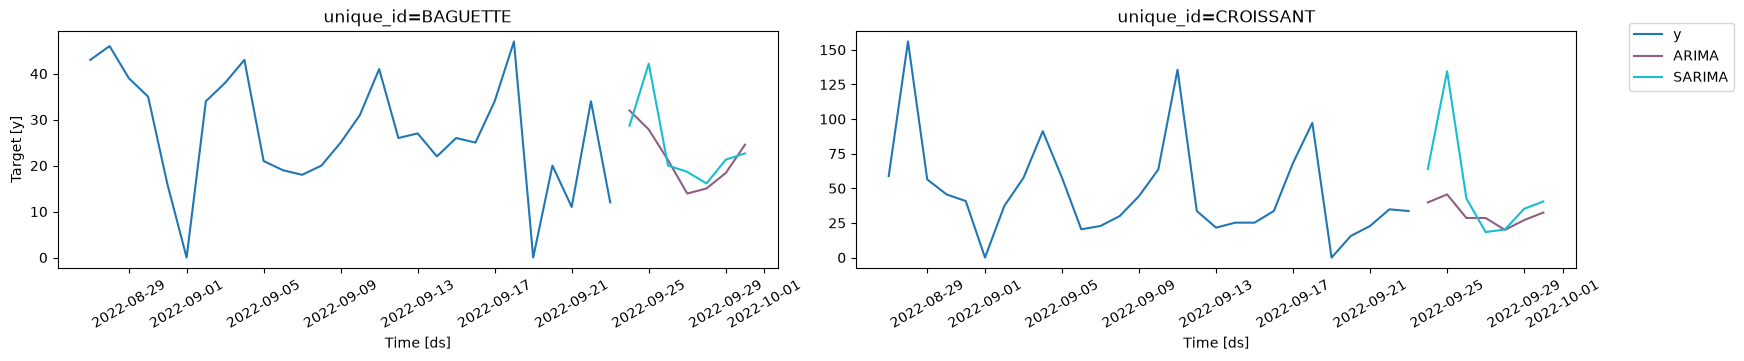

In [36]:
plot_series(
    df = sub_train, 
    forecasts_df = arima_preds,
    ids = ["BAGUETTE", "CROISSANT"], 
    # palette = "viridis", 
    max_insample_length = 28
)

 We can see that the ARIMA model struggles to capture the seasonal patterns in the data, whereas the seasonal model is able to closely mimic and understand the cyclic trend in the data. 

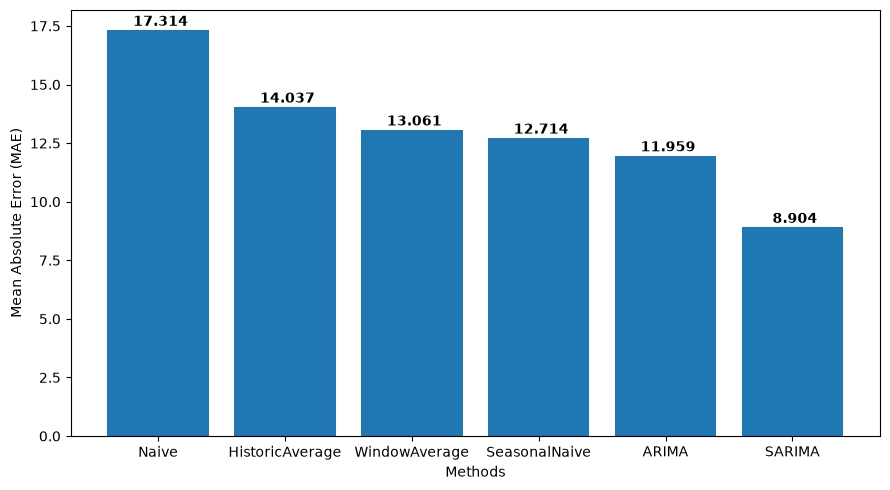

In [52]:
bar_chart_eval_viz(arima_eval, (9,5))

 **Observations:**      
 - We can see that the seasonal models are doing better than the rest of the models since they are able to capture the seasonal trend in the data, thereby producing a lower MAE score. 
 - Overall, Serima performs the best with the lowest MAE score, and the naive model performs the worst. 
 - Both ARIMA and SARIMA perform better than the baseline models. 

### Cross Validation

Keep the order of the data in mind while performing cross val on time series data. The initial window of training data is small and then you choose a small section following that window for prediction. The window then increases in a seqential order for the next set of forecasts.

In [8]:
unique_ids = ["BAGUETTE", "CROISSANT"]
horizon = 7
sub_df = grouped_df[grouped_df['unique_id'].isin(unique_ids)]

models = [
    SeasonalNaive(season_length = 7), # future values will repeat the values from the previous seasonal cycle.
    AutoARIMA(seasonal=False, alias = 'ARIMA'), # Disables seasonality
    AutoARIMA(season_length = 7, alias = 'SARIMA') # Specifies a weekly seasonal cycle.
]

sf = StatsForecast(models = models, freq = "D") # The frequency tells StatsForecast that each observation represents one day.
cv_df = sf.cross_validation(
    h = horizon, # forecasts for the next 7 days in each window
    df = sub_df, 
    n_windows = 8, # Perform 8 separate forecasting evaluations. (8 splits/windows)
    step_size = horizon, # The next window moves forward by 7 days (basically when doing the next iteration).
    refit = False # Do not retrain the models from scratch at every window.
)

# refit=True: The model is retrained at every cross-validation window using the expanded training dataset.
# refit=False: The model is fitted once and its fitted parameters are reused across subsequent windows.
# Since you have:
# - 2 products
# - 8 windows
# - 7 forecast days per window
# We have 2 x 8 x 7 = 112 forecasts

cv_df.head()

,unique_id,ds,cutoff,y,SeasonalNaive,ARIMA,SARIMA
0,BAGUETTE,2022-08-06,2022-08-05,55.0,68.0,59.804920,68.410279
1,BAGUETTE,2022-08-07,2022-08-05,67.0,70.0,59.151552,70.410279
2,BAGUETTE,2022-08-08,2022-08-05,61.0,48.0,51.913680,48.410279
3,BAGUETTE,2022-08-09,2022-08-05,52.0,49.0,50.534908,49.410279
4,BAGUETTE,2022-08-10,2022-08-05,57.0,57.0,56.846669,57.410279


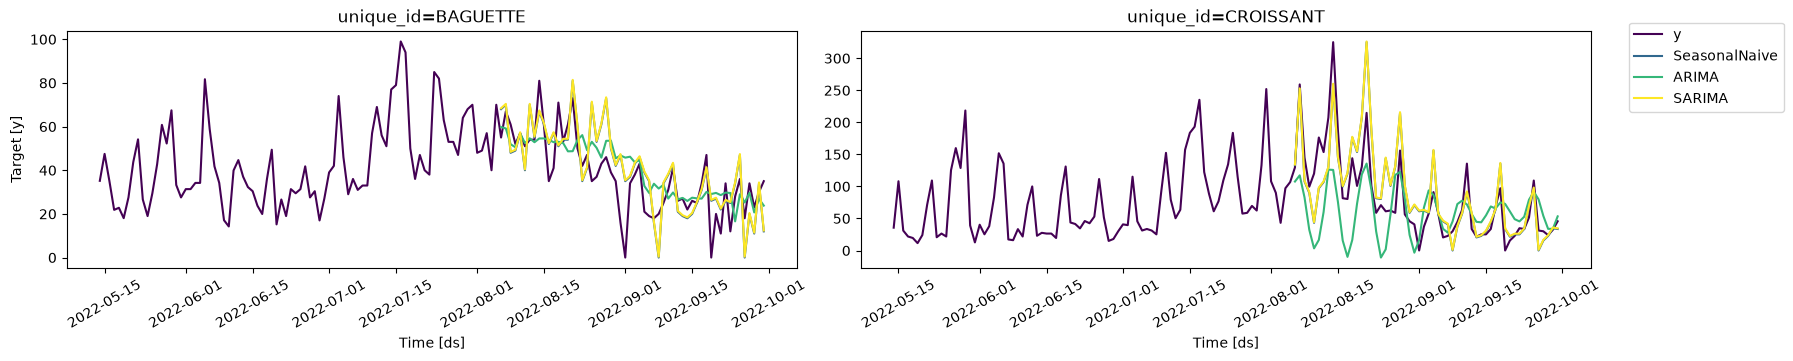

In [9]:
line_plot_forecast(grouped_df, cv_df)

In [10]:
cv_eval = evaluate(cv_df.drop(["cutoff"], axis = 1), metrics = [mae])
cv_eval = cv_eval.drop(["unique_id"], axis=1).groupby("metric").mean().reset_index()
cv_eval

,metric,SeasonalNaive,ARIMA,SARIMA
0,mae,21.117857,27.45233,21.263234


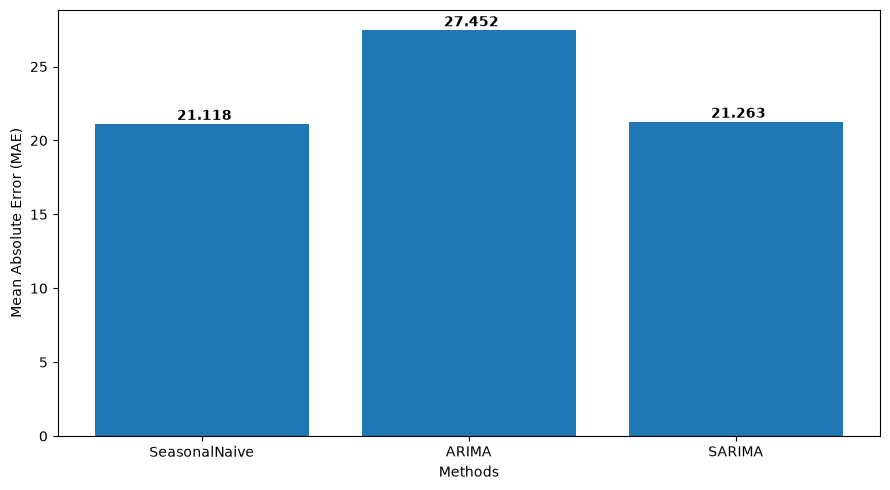

In [11]:
bar_chart_eval_viz(cv_eval, (9,5))

What's interesting is that the ARIMA model is performing worse than Seasonal Naive model (baseline model), on comparing multiple forecast windows.

### Forecasting with Exogenous Features

Exogenous features are external veriables that are not a part of the time series itself.        
There are 3 types of **Exogenous Features**:
1) Static - stay constant in time.
2) Historical - values known in the past but unknown in the future (eg. fuel prices).
3) Future - values know both in the past and the future (eg. dates of national holidays).

Creating Exgenous features (if we dont have any):
1) use fourier terms (sines and cosines) for seasonality. 
2) encode timestamps as features (day, month, etc.)

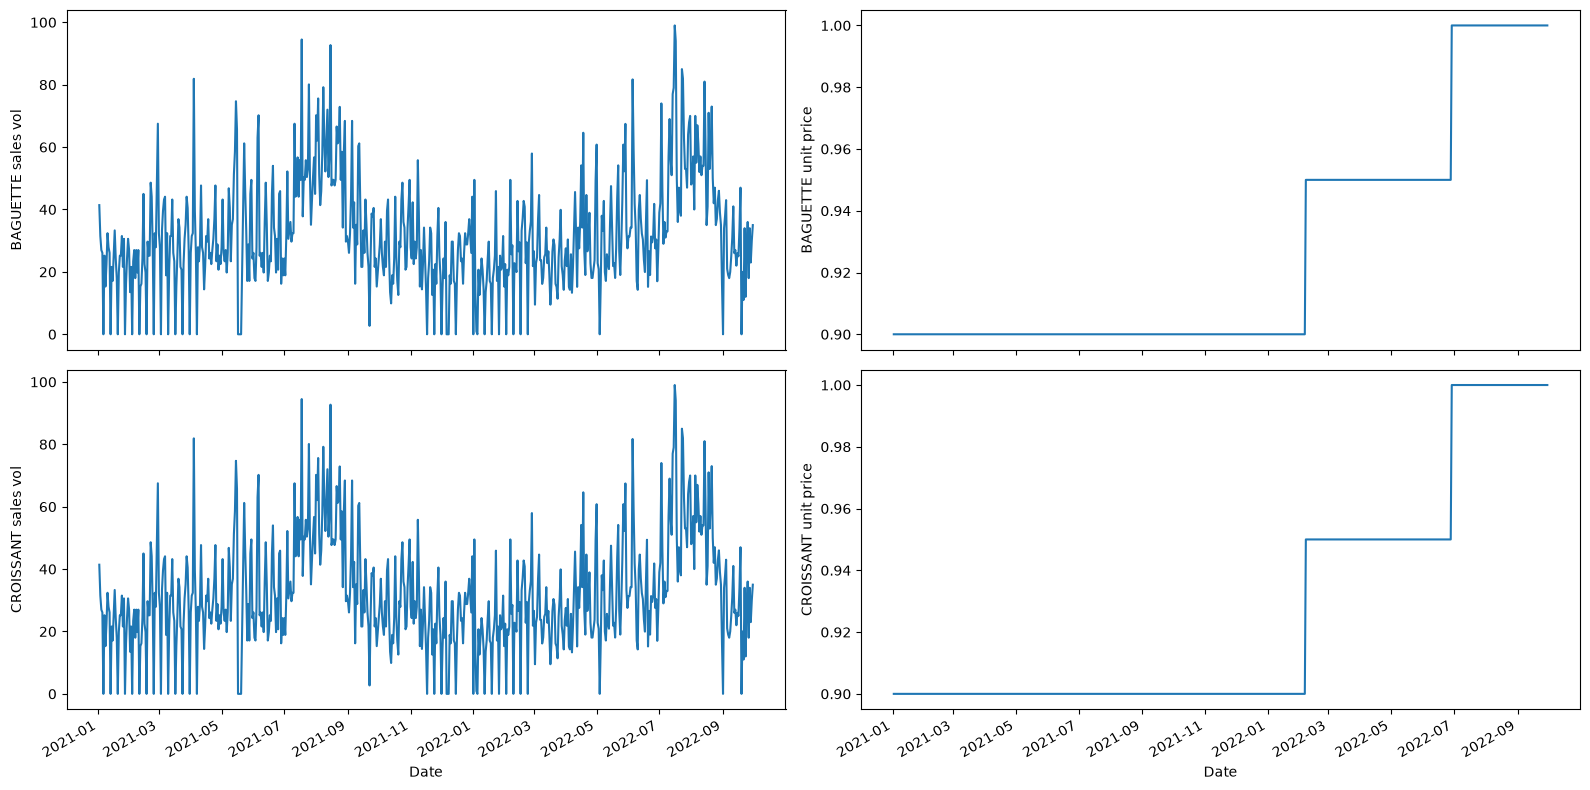

In [12]:
# Here we are using `Unit Price` as the exogenous variable
# Does the price of the item have an influence when forecasting the volume of sales 

df = pd.read_csv(data_path, parse_dates = ["ds"])
bag_df = df[df["unique_id"] == "BAGUETTE"]
croi_df = df[df["unique_id"] == "CROISSANT"]

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(
    nrows = 2, 
    ncols = 2, 
    figsize=(16,8)
)

ax1.plot(bag_df["ds"], bag_df["y"])
ax1.set_xlabel("Date")
ax1.set_ylabel("BAGUETTE sales vol")

ax2.plot(bag_df["ds"], bag_df["unit_price"])
ax2.set_xlabel("Date")
ax2.set_ylabel("BAGUETTE unit price")

ax3.plot(bag_df["ds"], bag_df["y"])
ax3.set_xlabel("Date")
ax3.set_ylabel("CROISSANT sales vol")

ax4.plot(bag_df["ds"], bag_df["unit_price"])
ax4.set_xlabel("Date")
ax4.set_ylabel("CROISSANT unit price")

fig.autofmt_xdate()
plt.tight_layout()

In [13]:
sub_df = df[df["unique_id"].isin(["BAGUETTE", "CROISSANT"])]
test = sub_df.groupby("unique_id").tail(7)
train = sub_df.drop(test.index).reset_index(drop=True)
exo_test_df = test.drop(["y"], axis = 1)

In [14]:
models = [AutoARIMA(season_length=7, alias = "SARIMA_exo")]

sf = StatsForecast(models=models, freq="D")
sf.fit(df=train)

arima_exo_preds = sf.predict(h=horizon, X_df=exo_test_df)


models = [AutoARIMA(season_length=7, alias = "SARIMA")]

sf = StatsForecast(models=models, freq="D")
sf.fit(df=train.drop(["unit_price"], axis= 1))

arima_preds = sf.predict(h=horizon)

In [15]:
test_df = test.merge(arima_exo_preds, on=["unique_id", "ds"], how = "left")\
.merge(arima_preds, on=["unique_id", "ds"], how = "left")

test_df.shape

(14, 6)

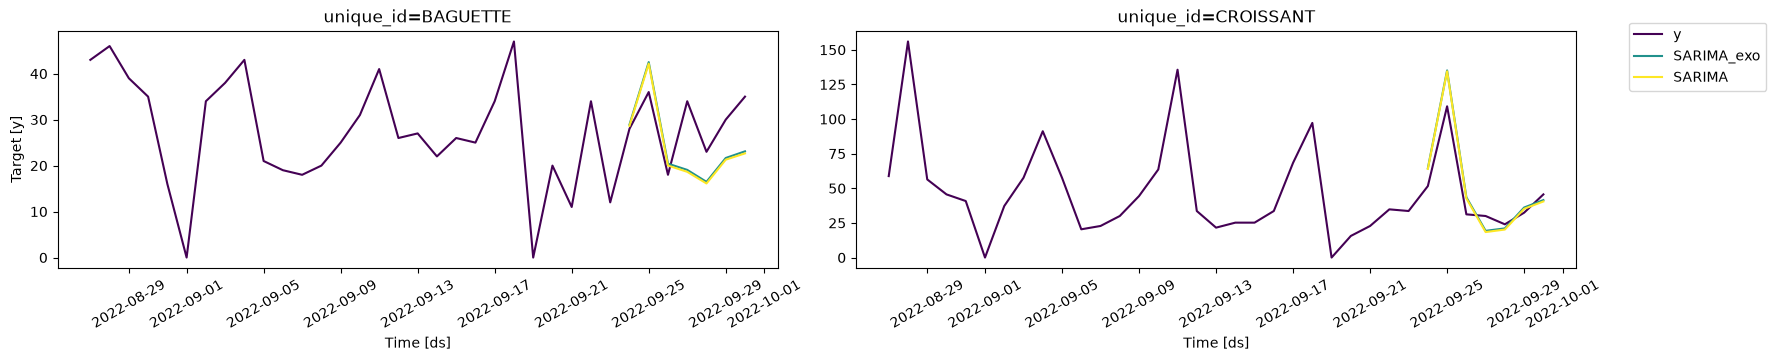

In [17]:
plot_series(
        df = train, 
        forecasts_df = test_df,
        ids = ["BAGUETTE", "CROISSANT"], 
        palette = "viridis",
        max_insample_length = 28,
        models = ["SARIMA_exo", "SARIMA"]
    )

In [18]:
## Running Cross Validation
models_exo = [AutoARIMA(season_length=7, alias = "SARIMA_exo")]

sf_exo = StatsForecast(models=models_exo, freq="D")
sf_exo.fit(df=train)

cv_exo_df = sf_exo.cross_validation(
    h =horizon,
    df = sub_df,
    n_windows=8,
    step_size= horizon,
    refit= True
)

cv_exo_df.head()

,unique_id,ds,cutoff,y,SARIMA_exo
0,BAGUETTE,2022-08-06,2022-08-05,55.0,71.511528
1,BAGUETTE,2022-08-07,2022-08-05,67.0,78.458054
2,BAGUETTE,2022-08-08,2022-08-05,61.0,57.062745
3,BAGUETTE,2022-08-09,2022-08-05,52.0,49.525901
4,BAGUETTE,2022-08-10,2022-08-05,57.0,49.485683


In [19]:
cv_exo_eval = evaluate(
    cv_exo_df.drop(["cutoff"], axis = 1),
    metrics = [mae]
)

cv_exo_eval

,unique_id,metric,SARIMA_exo
0,BAGUETTE,mae,8.934493
1,CROISSANT,mae,29.486034


In [20]:
cv_exo_eval = cv_exo_eval.drop(["unique_id"], axis = 1).groupby("metric").mean().reset_index()
cv_exo_eval

,metric,SARIMA_exo
0,mae,19.210264


### Creating features from Timestamps

In [ ]:
from functools import partial
from utilsforecast.feature_engineering import fourier, time_features, pipeline

In [ ]:
features = [
    partial(fourier, seasonal_length = 7, k=2),
    partial(time_features, features = ["day", "week", "month"])
]

train_exo_df, forecast_exo_df = pipeline(
    df = sub_df,
    features=features,
    freq = "D",
    h = horizon
)

# train and evaluate the data as how we have done before.

In [ ]:
train_exo_df.head()

### Prediction Intervals

A point forecast doesn't consider the uncertainty of the future. **Uncertainty** is measured with a prediction interval.        

A **prediction interval** is a range of values with an associated probability that the actual values are inside that range.         

For example, a 95% prediction interval means that there is a probability of 95% that the actual values fall within this range. 

In [4]:
df = pd.read_csv(data_path, parse_dates = ["ds"])
sub_df = df[df["unique_id"].isin(["BAGUETTE", "CROISSANT"])]
test = sub_df.groupby("unique_id").tail(7)
train = sub_df.drop(test.index).reset_index(drop=True)

In [ ]:
models = [
    AutoARIMA(season_length=7)
]
horizon = 7

sf = StatsForecast(models=models, freq = "D")
sf.fit(df = train)
prob_preds = sf.predict(h = 7, 
                        X_df = test.drop(["y"], axis = 1),
                        level = [80]                 
                        )

In [7]:
test_merged = test.merge(prob_preds, 
                         on = ["unique_id", "ds"], 
                         how = "left")

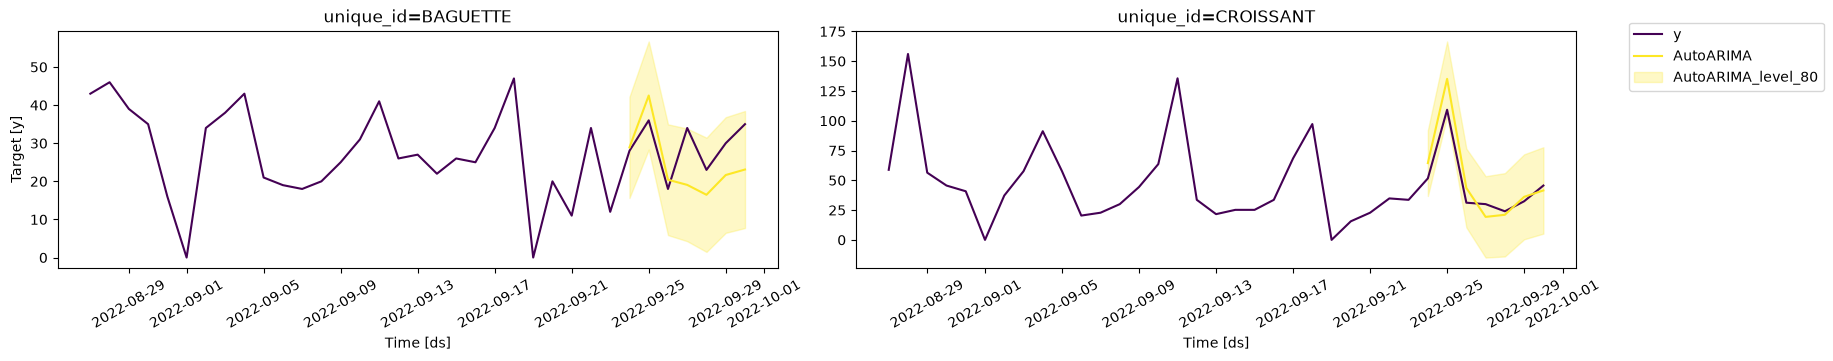

In [8]:
plot_series(
    df = train,
    forecasts_df=test_merged,
    ids = ["BAGUETTE", "CROISSANT"],
    max_insample_length= 28,
    models = ["AutoARIMA"],
    level = [80],
    palette="viridis"
)

In [9]:
## Cross validation
cv_prob_df = sf.cross_validation(
    h = horizon,
    df = sub_df,
    n_windows= 8,
    step_size=horizon,
    refit = True,
    level = [80]
)

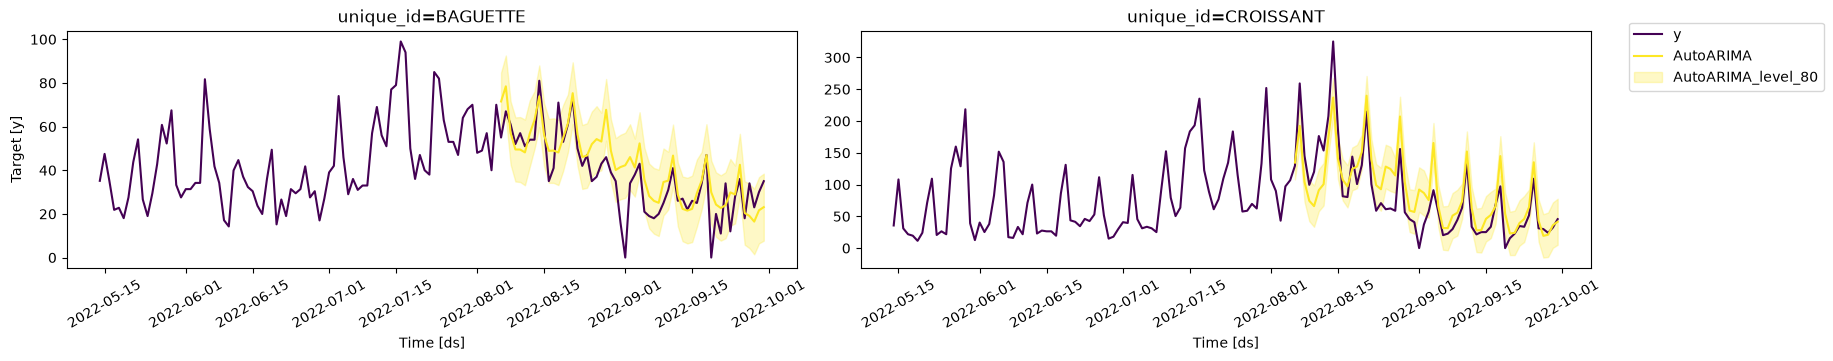

In [10]:
plot_series(
    df = sub_df,
    forecasts_df=cv_prob_df.drop(["y","cutoff"], axis = 1),
    ids = ["BAGUETTE", "CROISSANT"],
    max_insample_length= 140,
    models = ["AutoARIMA"],
    level = [80],
    palette="viridis"
)

### Evaluation Metrics

Point forecasts - MAE, MSE, RMSE, sMAPE, MASE       
Probabilistic forecasts - CRPS

MAE: Robust to outliers. Same units as the data.    
<br>
sMAPE (Symmetric mean absolute percentage error) : 
- Avoid if data is close to zero. 
- Equally sensitive to over- and under-forecasting.

<br>
MASE (Mean absolute scaled error) : Good if you are dealing with series of different scales 

<br>

CRPS (Continuous Ranked Probability Score) :
- Generalization of the MAE model for probabilistic forecasts 
- You care about the whole distribution. 

In [ ]:
models = [
    AutoARIMA(season_length=7, alias="SARIMA_exo"),
    SeasonalNaive(season_length=7)
]

sf = StatsForecast(models=models, freq="D")
cv_df = sf.cross_validation(
    h=horizon,
    sf = sub_df,
    n_windows = 8,
    step_size = 7,
    refit=True,
    level = [80],
)

In [ ]:
# Point and Period Predictions for both models
cv_df.head()

In [ ]:
temp_test = sub_df.groupby("unique_id").tail(7*8)
temp_train = sub_df.drop(temp_test.index).reset_index(drop=True)

In [ ]:
models =[
    "SARIMA_exo", "SeasonalNaive"
]
metrics = [
    mae, mse, rmse, 
    mape, smape,
    partial(mase, seasonality = 7),
    scaled_crps
]

final_eval = evaluate(cv_df.drop(["ds", "cutoff"], axis = 1), 
                      metircs = metrics,
                      models = models,
                      train_df = temp_train,
                      level = [80]
                      )

final_eval = final_eval.drop(["unique_id"], axis = 1)\
                       .groupby("metric")\
                       .mean()\
                       .reset_index()

In [ ]:
fig, axes = plt.subplots(3,3, figsize=(18,12))
axes_flat = axes.flatten()

x_pos = [0,1]
colours = ['blue', 'red']

for i, row in final_eval.iterrows():
    ax = axes_flat[i]

    model_values = [row["SARIMA_exo"], row["SeasonalNaive"]]
    bars = ax.bar(x_pos, 
                  model_values, 
                  color = colours, 
                  alpha = 0.8,
                  edgecolor = "black",
                  linewidth = 1
                  )

    for j, (bar, value) in enumerate(zip(bars, model_values)):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2.0 ,
                height + height*0.01,
                f'{value:.3f}', ha = "center", va = "bottom",
                fontweight = "bold", fontsize = 10)

    ax.set_title(row['metric'].upper(), fontweight = "bold", fontsize=12)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(models, ha = "center")
    ax.set_ylabel("Value")
    max_value = max(model_values)
    ax.set_ylim(0, max_value * 1.1)

fig.delaxes(axes_flat[7])
axes_flat[8].set_visible(False)

plt.tight_layout()
plt.show()

    